# System reliability

*Beyond the scriptum — an application.*

---

An aircraft has three hydraulic circuits, a server two power supplies, a power plant several
independent cooling loops. The question is always the same:

> What is the probability that the system as a whole fails?

For simple wirings it can be computed by a formula. For complex ones it cannot be computed at all —
and simulation is the only way. And when the system is meant to be really reliable, we run into an old
acquaintance: **a failure is so rare that plain Monte Carlo never sees it**.

It is the same problem as the rare ruin of the insurance company in `insurance_realistic`, only in
different words. And it is solved the same way — by the **importance sampling** of exercise 7.

You will see:

- series and parallel wiring, and an exact formula as a check
- why redundancy helps so much (and when it does not)
- rare failures, where plain MC fails and the weighting does not

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)


# the system: BLOCKS blocks wired in series, each block has PER_BLOCK backups in parallel
BLOCKS = 3
PER_BLOCK = 2

## 1. In series and in parallel

Two basic wirings:

- **In series**: the system works only when **all** the parts work. The reliabilities multiply,
  $R = \prod R_i$. Every additional part makes the system **worse**.
- **In parallel** (redundancy): it is enough for **at least one** to work. It fails only when all of
  them fail: $R = 1 - \prod (1 - R_i)$. Every additional backup makes the system **better**.

Our system is a combination: $B$ blocks in series, each block having $k$ backups. A block fails with
probability $q^k$, and the system fails when at least one block fails:

$$R_{\text{system}} = \big(1 - q^{k}\big)^{B}.$$

This formula is our exact check.

In [2]:
def reliability_exact(q, blocks=BLOCKS, per_block=PER_BLOCK):
    '''The probability that the system works.'''
    return (1 - q**per_block) ** blocks


def failure_exact(q, **kw):
    return 1 - reliability_exact(q, **kw)


def system_fails(q, blocks=BLOCKS, per_block=PER_BLOCK):
    '''One simulation: does at least one block fail?'''
    for _ in range(blocks):
        if all(random.random() < q for _ in range(per_block)):
            return True
    return False


print(f"the system: {BLOCKS} blocks in series, each with {PER_BLOCK} backups\n")
print(f"{'q (a component)':>16s} {'simulation':>22s} {'exact':>12s}")
for q in (0.2, 0.1, 0.05, 0.01):
    M_ = 200_000
    vals = [1.0 if system_fails(q) else 0.0 for _ in range(M_)]
    m, se = estimate(vals)
    print(f"{q:>16.3f} {m:>14.5f} +- {se:.5f} {failure_exact(q):>12.5f}")
    assert abs(m - failure_exact(q)) < 5 * se

the system: 3 blocks in series, each with 2 backups

 q (a component)             simulation        exact
           0.200        0.11560 +- 0.00071      0.11526


           0.100        0.02926 +- 0.00038      0.02970
           0.050        0.00760 +- 0.00019      0.00748


           0.010        0.00026 +- 0.00004      0.00030


## 2. How much redundancy pays off

Redundancy has sharply diminishing returns — and it is worth seeing how sharply. A block with $k$
backups fails with probability $q^k$, so every additional backup multiplies the block's risk by $q$.

At the same time, though, the unpleasant side of the series wiring applies: **there are more blocks
and it is enough for one to fail.**

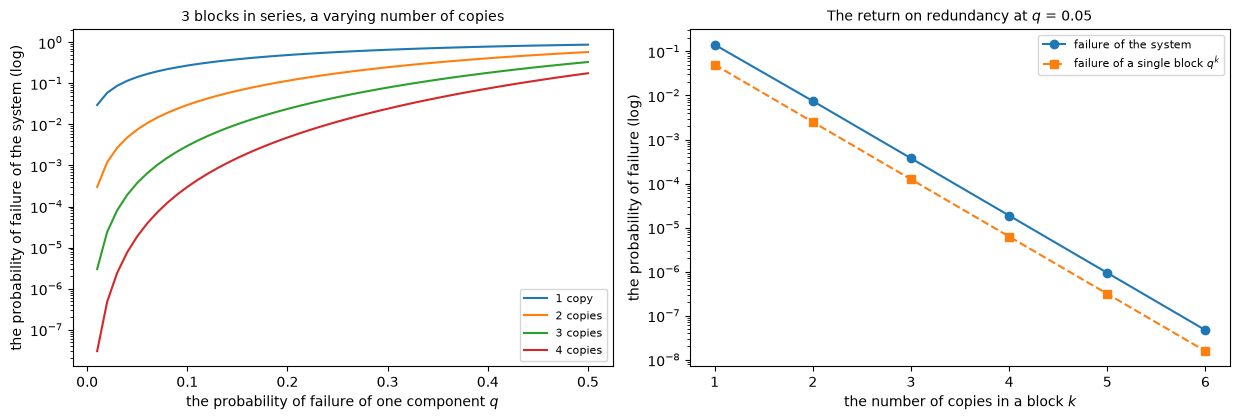

at q = 0.05:
  1 copies: a block fails with 5.0e-02, the system with 1.4e-01
  2 copies: a block fails with 2.5e-03, the system with 7.5e-03
  3 copies: a block fails with 1.3e-04, the system with 3.7e-04
  4 copies: a block fails with 6.3e-06, the system with 1.9e-05

The system is roughly 3 times worse than one block — the series wiring
multiplies the risk by the number of blocks. Redundancy pays off, but first you need
to know WHICH block is the weakest; adding backups to one that is already good helps next to nothing.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
qq = [0.01 * i for i in range(1, 51)]
for k in (1, 2, 3, 4):
    ax.semilogy(qq, [failure_exact(q, per_block=k) for q in qq], label=f"{k} " + ("copy" if k == 1 else "copies"))
ax.set_xlabel("the probability of failure of one component $q$")
ax.set_ylabel("the probability of failure of the system (log)")
ax.set_title(f"{BLOCKS} blocks in series, a varying number of copies", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
q = 0.05
ks = list(range(1, 7))
ax.semilogy(ks, [failure_exact(q, per_block=k) for k in ks], "o-", label="failure of the system")
ax.semilogy(ks, [q**k for k in ks], "s--", label="failure of a single block $q^k$")
ax.set_xlabel("the number of copies in a block $k$")
ax.set_ylabel("the probability of failure (log)")
ax.set_title(f"The return on redundancy at $q$ = {q}", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"at q = {q}:")
for k in (1, 2, 3, 4):
    print(f"  {k} copies: a block fails with {q**k:.1e}, the system with {failure_exact(q, per_block=k):.1e}")
print(f"\nThe system is roughly {BLOCKS} times worse than one block — the series wiring")
print(f"multiplies the risk by the number of blocks. Redundancy pays off, but first you need")
print(f"to know WHICH block is the weakest; adding backups to one that is already good helps next to nothing.")

## 3. When the failure is really rare

For reliable systems the interesting values of $q$ are around $10^{-3}$ and smaller. There the
probability of system failure is around $10^{-6}$ and lower — and plain Monte Carlo stops working,
because out of a million runs it does not record a single one.

The solution is the same as for the rare ruin of the insurance company: **we generate with an inflated
failure probability $q'$ and weight by the likelihood ratio.** For each component separately

$$w = \begin{cases} q/q', & \text{the component failed},\\[1mm] (1-q)/(1-q'), & \text{the component works},\end{cases}$$

and the weight of the whole run is the product over all the components.

In [4]:
def failure_weighted(q, q_proposal=0.05, M_=50_000):
    '''The probability of failure by importance sampling.'''
    values = []
    for _ in range(M_):
        w, failed = 1.0, False
        for _ in range(BLOCKS):
            block = [random.random() < q_proposal for _ in range(PER_BLOCK)]
            for component_failed in block:
                w *= (q / q_proposal) if component_failed else ((1 - q) / (1 - q_proposal))
            if all(block):
                failed = True
        values.append(w if failed else 0.0)
    return estimate(values)


def failure_plain(q, M_=200_000):
    hits = sum(system_fails(q) for _ in range(M_))
    ph = hits / M_
    return ph, math.sqrt(max(ph * (1 - ph), 1e-30) / M_), hits


print(f"{'q':>8s} {'exact':>12s} | {'plain MC (200 000)':>28s} | {'weighting (50 000)':>26s}")
qs, errs_plain, errs_weighted = [], [], []
for q in (1e-2, 1e-3, 1e-4, 1e-5):
    exact = failure_exact(q)
    pl, se_pl, hits = failure_plain(q)
    wt, se_wt = failure_weighted(q)
    qs.append(q); errs_plain.append(se_pl); errs_weighted.append(se_wt)
    print(f"{q:>8.0e} {exact:>12.3e} | {pl:>12.3e} +- {se_pl:>8.1e} ({hits:>3d} hits) "
          f"| {wt:>12.3e} +- {se_wt:>8.1e}")
    assert abs(wt - exact) < 5 * se_wt, q

print("\nFrom q = 1e-3 on, plain MC does not find a single hit and returns zero with zero error —")
print("a confident claim that the system cannot fail. The weighting gives the right order of magnitude")
print("and a usable error bar, and does so with a QUARTER of the number of runs.")

       q        exact |           plain MC (200 000) |         weighting (50 000)
   1e-02    3.000e-04 |    3.250e-04 +-  4.0e-05 ( 65 hits) |    2.922e-04 +-  1.6e-05


   1e-03    3.000e-06 |    0.000e+00 +-  2.2e-18 (  0 hits) |    2.790e-06 +-  1.6e-07


   1e-04    3.000e-08 |    0.000e+00 +-  2.2e-18 (  0 hits) |    2.888e-08 +-  1.7e-09


   1e-05    3.000e-10 |    0.000e+00 +-  2.2e-18 (  0 hits) |    3.369e-10 +-  1.8e-11

From q = 1e-3 on, plain MC does not find a single hit and returns zero with zero error —
a confident claim that the system cannot fail. The weighting gives the right order of magnitude
and a usable error bar, and does so with a QUARTER of the number of runs.


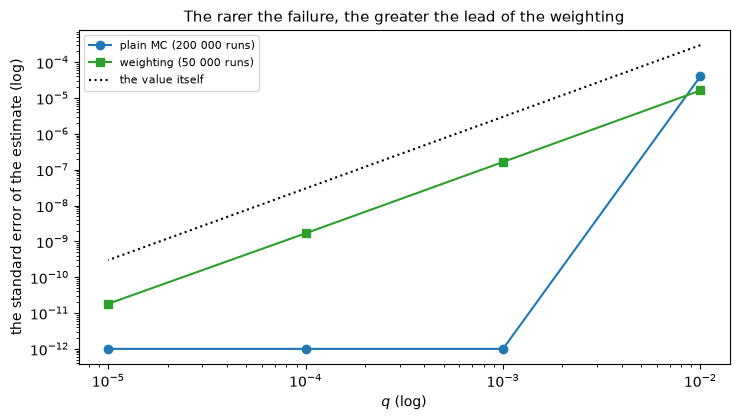

The dotted line is the sought value itself. Where the error curve crosses it,
the estimate is worthless — the error is larger than the result. Plain MC
gets there around q ≈ 1e-3, the weighting stays several orders of magnitude lower.


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.loglog(qs, [max(c, 1e-12) for c in errs_plain], "o-", label="plain MC (200 000 runs)")
ax.loglog(qs, errs_weighted, "s-", color="tab:green", label="weighting (50 000 runs)")
ax.loglog(qs, [failure_exact(q) for q in qs], "k:", label="the value itself")
ax.set_xlabel("$q$ (log)")
ax.set_ylabel("the standard error of the estimate (log)")
ax.set_title("The rarer the failure, the greater the lead of the weighting", fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("The dotted line is the sought value itself. Where the error curve crosses it,")
print("the estimate is worthless — the error is larger than the result. Plain MC")
print("gets there around q ≈ 1e-3, the weighting stays several orders of magnitude lower.")

## Summary

| Concept | What to remember |
|---------|------------------|
| Series wiring | works only when **everything** works; $R = \prod R_i$, every part makes it worse |
| Parallel (backups) | **one** suffices; a block fails with $q^k$, every backup multiplies the risk by $q$ |
| Our system | $B$ blocks in series of $k$ copies each ⟹ $R = (1-q^k)^B$ |
| Sharply diminishing returns | adding backups to an already reliable block is pointless; find the weakest |
| Rare failures | plain MC returns **zero with zero error** — a confident nonsense |
| The weighting | $w = q/q'$ for a failed and $(1-q)/(1-q')$ for a working component |
| The check | $q' = q$ returns plain MC; the formula $(1-q^k)^B$ guards correctness |

The same material as the rare ruin in `insurance_realistic` — different words, the same mathematics.
That is, incidentally, a good reason to learn the method and not just the problem.

### Try it yourself

1. Find the optimal $q'$ for $q = 10^{-5}$: try several values and watch the standard error. Does it
   hold here too that the optimum is where the event becomes typical?
2. Make a "$k$ out of $n$" system (it works when at least $k$ of $n$ components work). The exact
   probability is binomial — verify it.
3. Introduce a **common cause**: with probability $\varepsilon$ all the components of a block fail at
   once (a power cut). How much does that spoil the redundancy?
4. Let the components age: $q$ grows with time according to a Weibull distribution. Compute the
   probability of failure during a year of operation.
5. With a budget for one extra backup — which block should it go to when the blocks have different
   $q$? Verify by simulation.
6. Compare the weighting with **stratification** by the number of failed components (exercise 7).
   Which method is better here?